# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Muhammad Anees
- **Student ID:** 023-24-0251
- **Section:** H
- **GitHub:**https://github.com/Anees-Memon-Hub/ML-Practice
- **Kaggle:**https://www.kaggle.com/aneesmemon
- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 100

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [28]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nGender counts:")
print(df["Gender"].value_counts())

print("\nSummary of Age, Income and Spending:")
display(df[["Age", "Income", "Spending"]].describe().round(2))

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64

Summary of Age, Income and Spending:


,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


**Interpretation:** The dataset is tidy: 200 observations, 5 variables, no missing entries, and no repeated rows. The number of women is 112 and men is 88. The income ranges between 15 to 137 (k$) with the mean value 60.56, and spending score varies between 1 to 99 with the mean 50.2. The income and spending are almost equally distributed with std 26.26 and 25.82 while age distribution has std 13.97 with range 18 to 70.

### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

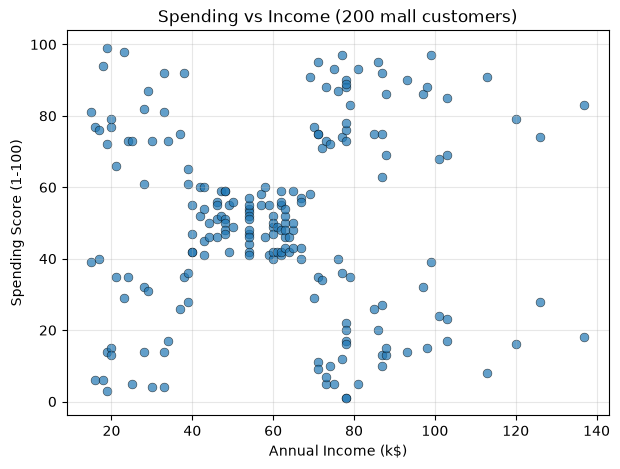

In [29]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Income"], df["Spending"], s=40, alpha=0.7, edgecolor="k", linewidth=0.4)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Spending vs Income (200 mall customers)")
plt.grid(alpha=0.3)
plt.show()

**Interpretation:** The points are not spread evenly. There is a thick cloud in the middle (income about 40 to 70, spending about 40 to 60) and four smaller groups sitting in the four corners of the plot. So the scatter already suggests a natural number of groups before we run any algorithm.

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

**(a)** Five groups can be seen by eye:
1. **Middle group:** middle-income (between about 40 and 70 k$) and medium expenditure (between 40 and 60). This is the largest and most dense group.
2. **High income, high expenditure:** top right corner (above ~70 for income, above ~65 for expenditure).
3. **High income, low expenditure:** bottom right corner (above ~70 for income, below ~40 for expenditure).
4. **Low income, high expenditure:** top left corner (below ~40 for income, above ~60 for expenditure).
5. **Low income, low expenditure:** bottom left corner (below ~40 for income, below ~40 for expenditure).

**(b)** Accuracy makes a comparison between the prediction and actual label, but since we don’t have a label column, there is nothing to compare against. Train/test split is irrelevant because in the K-Means algorithm, there is no learning of any rule that can be used to predict a target. The cluster numbers generated are subjective because in one trial, cluster 2 could be cluster 4 in another trial. Thus, the only way we can validate our clusters is by using the inertia value, silhouette score, plotting, and whether the clusters make sense from a business perspective.

---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [30]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])          # starting centroids from the lecture

for it in range(1, 20):
    dist = np.abs(x[:, None] - m[None, :])        # shape (9, 2)
    labels = dist.argmin(axis=1)                  # 0 -> C1, 1 -> C2
    new_m = np.array([x[labels == k].mean() for k in range(2)])

    print(f"Iteration {it}")
    print("   C1:", x[labels == 0].tolist(), "  C2:", x[labels == 1].tolist())
    print("   new centroids:", new_m)

    if np.allclose(new_m, m):
        print("   -> centroids did not change, stop.\n")
        break
    m = new_m

inertia = ((x - m[labels]) ** 2).sum()
print("Final centroids:", m)
print("Inertia:", inertia)
print("Matches lecture (centroids 7 and 25, inertia 150)?",
      np.allclose(m, [7, 25]) and np.isclose(inertia, 150))

Iteration 1
   C1: [2.0, 4.0, 3.0]   C2: [10.0, 12.0, 20.0, 30.0, 11.0, 25.0]
   new centroids: [ 3. 18.]
Iteration 2
   C1: [2.0, 4.0, 10.0, 3.0]   C2: [12.0, 20.0, 30.0, 11.0, 25.0]
   new centroids: [ 4.75 19.6 ]
Iteration 3
   C1: [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]   C2: [20.0, 30.0, 25.0]
   new centroids: [ 7. 25.]
Iteration 4
   C1: [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]   C2: [20.0, 30.0, 25.0]
   new centroids: [ 7. 25.]
   -> centroids did not change, stop.

Final centroids: [ 7. 25.]
Inertia: 150.0
Matches lecture (centroids 7 and 25, inertia 150)? True


**Interpretation:** The loop needed 3 iterations to move the centroids and a 4th one just to confirm nothing changed. It ended at centroids **7 and 25** with inertia **150**, exactly the numbers on the lecture slides, so my assign/update steps are correct.

### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [31]:
def my_kmeans(X, init_centroids, max_iter=100):
    """Plain K-Means (Lloyd). Works for any number of features.
    Returns labels, centroids, inertia, number of iterations."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:                       # allow a simple 1-D list of numbers
        X = X.reshape(-1, 1)
    c = np.asarray(init_centroids, dtype=float)
    if c.ndim == 1:
        c = c.reshape(-1, 1)
    K = c.shape[0]

    for it in range(1, max_iter + 1):
        # assign step: distance of every point to every centroid -> (n, K)
        dist = np.sqrt(((X[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
        labels = dist.argmin(axis=1)

        # update step: move each centroid to the mean of its points
        new_c = c.copy()
        for k in range(K):
            if np.any(labels == k):       # if a cluster becomes empty, keep the old centroid
                new_c[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_c, c):         # converged
            break
        c = new_c

    inertia = ((X - c[labels]) ** 2).sum()
    return labels, c, inertia, it


# test on Example 1 from the lecture
lab, cen, inert, n_it = my_kmeans(x, [4, 11])
print("Centroids:", cen.ravel(), "| inertia:", inert, "| iterations:", n_it)
assert np.allclose(sorted(cen.ravel()), [7, 25]) and np.isclose(inert, 150)
print("Example 1 test passed.")

Centroids: [ 7. 25.] | inertia: 150.0 | iterations: 4
Example 1 test passed.


In [32]:
X2 = df[["Income", "Spending"]].values.astype(float)     # 200 x 2
init5 = X2[:5].copy()                                     # first 5 rows as starting centroids

# my function
lab_m, cen_m, inert_m, it_m = my_kmeans(X2, init5)

# scikit-learn with exactly the same start
sk = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)

print(f"my_kmeans : inertia = {inert_m:.4f}, iterations = {it_m}")
print(f"sklearn   : inertia = {sk.inertia_:.4f}, iterations = {sk.n_iter_}")
print("Same label for every customer?", np.array_equal(lab_m, sk.labels_))
print("Max abs difference in centroids:", np.abs(cen_m - sk.cluster_centers_).max())

comp = pd.DataFrame({
    "my Income": cen_m[:, 0].round(3), "my Spending": cen_m[:, 1].round(3),
    "sk Income": sk.cluster_centers_[:, 0].round(3), "sk Spending": sk.cluster_centers_[:, 1].round(3),
})
comp.index.name = "centroid"
display(comp)

my_kmeans : inertia = 44448.4554, iterations = 4
sklearn   : inertia = 44448.4554, iterations = 4
Same label for every customer? True
Max abs difference in centroids: 2.842170943040401e-14


,my Income,my Spending,sk Income,sk Spending
centroid,,,,
0,26.304,20.913,26.304,20.913
1,25.727,79.364,25.727,79.364
2,88.200,17.114,88.200,17.114
3,86.538,82.128,86.538,82.128
4,55.296,49.519,55.296,49.519


**Interpretation:** Using the identical five rows to start with, my algorithm and the scikit-learn provide the identical inertia value (44448.4554), the identical centroid values, and the identical clusters for each and every one of the 200 customers.

**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

**(a)** In iteration 1, the values of the centroids were 4 and 11. The distance between 10 and 4 is 6 while that between 10 and 11 is just 1, so it got clustered at C2. After the re-computation step, the new values for centroids were **3** (average of 2, 4, and 3) and **18** (average of 10, 12, 20, 30, 11, and 25). Clearly the large values 20, 30, and 25 increased the value of C2 centroid from 11 to 18. In iteration 2, the distance between 10 and C1 is |10 – 3| = 7, and that between 10 and C2 is |10 – 18| = 8, so it moved to C1.
**(b)** The program ends once the assignments (centroids) don't change between two consecutive runs of the loop. This happens due to the fact that both of the operations decrease the inertia of the clusters or leave it unchanged – the assignment operation assigns each of the points the nearest centroid, while the update operation places the centroids at the mean position, which is the position minimizing the sum of squared distances. Since there can't be an infinite decreasing of inertia and there is a limited number of possible partitions of 200 points into five clusters, the program should stop once nothing changes. However, it stops at a *local minimum*.
**(c)** Yes, it did match. The inertia of 44448.4554 is common to both, the 5 centroids are the same (the maximum deviation is of the floating-point kind, i.e., around 3e-14), and all the customers received the same classification. They both stopped in the same 4 iterations. There can be the only small difference due to different summation order in NumPy vs. scikit-learn.

---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

 K  Inertia  Silhouette  Inertia drop
 2 181363.6      0.2969           NaN
 3 106348.4      0.4676       75015.2
 4  73679.8      0.4932       32668.6
 5  44448.5      0.5539       29231.3
 6  37233.8      0.5398        7214.6
 7  30241.3      0.5288        6992.5
 8  25036.4      0.4548        5204.9
 9  21916.8      0.4561        3119.6
10  20072.1      0.4411        1844.7


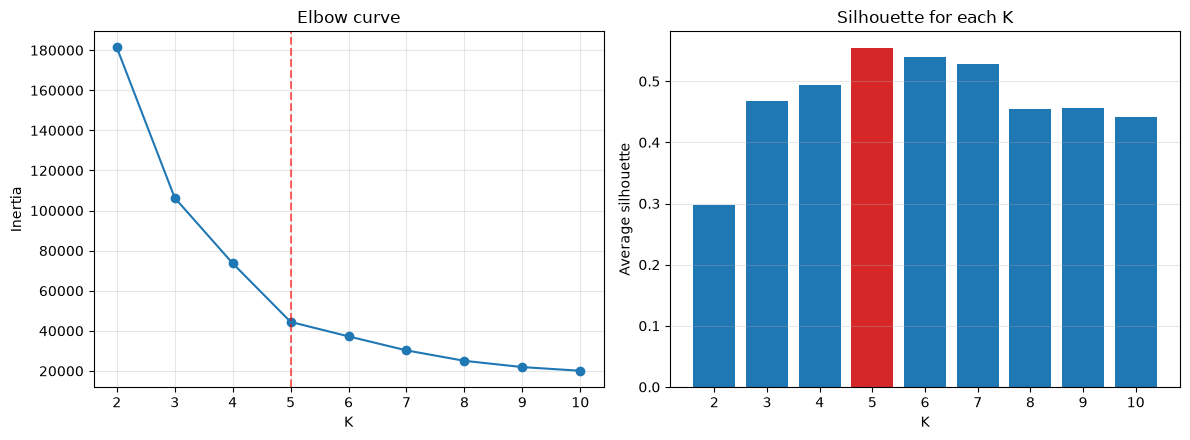

K with the highest silhouette: 5 -> 0.5539


In [33]:
rows = []
for K in range(2, 11):
    km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X2)
    rows.append((K, km.inertia_, silhouette_score(X2, km.labels_)))

res = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
res["Inertia drop"] = (-res["Inertia"].diff()).round(1)      # how much inertia fell compared to K-1
res["Inertia"] = res["Inertia"].round(1)
res["Silhouette"] = res["Silhouette"].round(4)
print(res.to_string(index=False))          # <-- changed line

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(res["K"], res["Inertia"], "o-")
ax[0].axvline(5, color="red", ls="--", alpha=0.6)
ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow curve")
ax[0].grid(alpha=0.3)

best_K = int(res.loc[res["Silhouette"].idxmax(), "K"])
colors = ["tab:red" if k == best_K else "tab:blue" for k in res["K"]]
ax[1].bar(res["K"], res["Silhouette"], color=colors)
ax[1].set_xlabel("K"); ax[1].set_ylabel("Average silhouette"); ax[1].set_title("Silhouette for each K")
ax[1].set_xticks(res["K"]); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

print("K with the highest silhouette:", best_K, "->", res.loc[res["K"] == best_K, "Silhouette"].values[0])

**Interpretation:** The inertia falls quickly until K = 5 and then the drops get small (29231 from K=4 to 5, but only 7215 from K=5 to 6). So the elbow is at K = 5. The silhouette bars peak at K = 5 (0.5539) and go down after that.

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [34]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def silhouette_one(X, labels, i):
    """a, b and s for the single point i, using only NumPy distances."""
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))      # distance from point i to every point
    own = labels[i]
    same = (labels == own)
    same[i] = False                                  # do not count the point itself
    a = d[same].mean()
    others = [k for k in np.unique(labels) if k != own]
    b = min(d[labels == k].mean() for k in others)   # nearest other cluster
    return a, b, (b - a) / max(a, b), {k: d[labels == k].mean() for k in others}

a, b, s, per_cluster = silhouette_one(X2, lab5, 0)
s_sklearn = silhouette_samples(X2, lab5)[0]

print("Customer 1: Income =", X2[0, 0], " Spending =", X2[0, 1], " cluster =", lab5[0])
print("Average distance to the other clusters:", {k: round(v, 2) for k, v in per_cluster.items()})
print(f"a = {a:.4f}   b = {b:.4f}")
print(f"s (my function)       = {s:.6f}")
print(f"s (silhouette_samples) = {s_sklearn:.6f}")
print("Same value?", np.isclose(s, s_sklearn))

Customer 1: Income = 15.0  Spending = 39.0  cluster = 4
Average distance to the other clusters: {np.int32(0): np.float64(42.27), np.int32(1): np.float64(84.28), np.int32(2): np.float64(42.53), np.int32(3): np.float64(77.26)}
a = 24.6404   b = 42.2653
s (my function)       = 0.417005
s (silhouette_samples) = 0.417005
Same value? True


**Interpretation:** My individual calculation for customer 1 yields a value of a = 24.64 and b = 42.27. This gives a silhouette coefficient of (42.27 – 24.64) / 42.27 = 0.417, which is equal to that of `silhouette_samples`.

**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote your numbers.

(b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?

(c) Why should we never choose K only by the lowest inertia?

**Your answers:**

**(a)** Based on the elbow chart, the value of **K = 5**. The inertia decreases by 75015 (from K=2 to 3), 32669 (from 3 to 4), 29231 (from 4 to 5), but then just 7215 (from 5 to 6), and 6993 (from 6 to 7); hence, the chart shows a bend at 5. Based on the silhouette method, the value is also at **K = 5**, which has the value of 0.5539 (at K=6, 0.5398; at K=7, 0.5288; at K=2, 0.2969). Therefore, the two methods **concur**, and hence I choose K = 5.

**(b)** Customer 1 (Income 15, Spending 39) has **s = 0.417** (a = 24.64, b = 42.27). Since the score is a positive number, the customer belongs to the correct group (low income, low spending), although it does not belong to the deepest part of it. The expenditure of the customer equals 39, which is higher than the average expenditure of that group, around 21. Therefore, the customer belongs to the top part of his group. The next closest cluster is the middle group (distance 42.27), while the low income / high spending cluster has nearly the same distance (42.53).

**(c)** When K increases, inertia decreases since there will be more centroids hence every data point will be near a centroid. If K = 200 (all customers make clusters) then inertia = 0 and that’s of no use. From my analysis, increasing the value of K from 5 (inertia 44449) to 10 (20072) reduced the inertia by half, but the silhouette score reduces from 0.554 to 0.441 hence making the clusters less separated than before.

---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

init='random',    n_init=1
   lowest inertia : 44448.5
   highest inertia: 91762.0
   distinct values: 14
   runs that reached the lowest value: 10 out of 30

init='k-means++', n_init=10
   lowest inertia : 44448.5
   highest inertia: 44448.5
   distinct values: 1
   runs that reached the lowest value: 30 out of 30



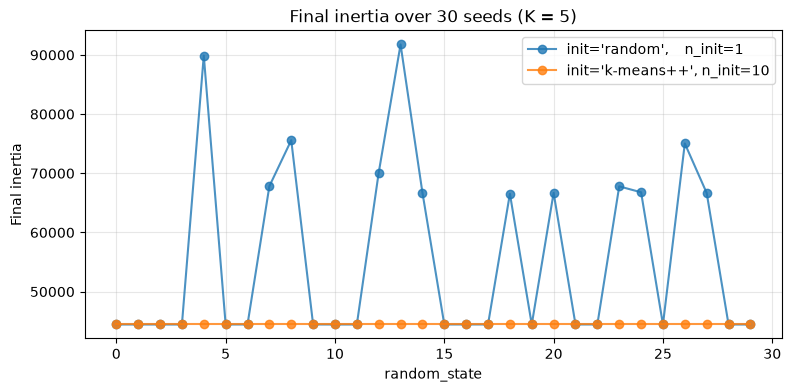

In [35]:
def run_30(init, n_init):
    vals = []
    for s in range(30):                                   # random_state = 0 ... 29
        km = KMeans(n_clusters=5, init=init, n_init=n_init, random_state=s).fit(X2)
        vals.append(km.inertia_)
    return np.array(vals)

runs = {
    "init='random',    n_init=1":  run_30("random", 1),
    "init='k-means++', n_init=10": run_30("k-means++", 10),
}

for name, v in runs.items():
    r = np.round(v, 1)
    uniq, cnt = np.unique(r, return_counts=True)
    print(name)
    print("   lowest inertia :", r.min())
    print("   highest inertia:", r.max())
    print("   distinct values:", len(uniq))
    print("   runs that reached the lowest value:", int((r == r.min()).sum()), "out of 30")
    print()

plt.figure(figsize=(9, 4))
for name, v in runs.items():
    plt.plot(range(30), v, "o-", label=name, alpha=0.8)
plt.xlabel("random_state"); plt.ylabel("Final inertia")
plt.title("Final inertia over 30 seeds (K = 5)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretation:**Using a single starting point, the final inertia ranges from 44448.5 to 91762.0, meaning that there will be runs with a value two times larger than the smallest one. In the case of k-means++ with 10 starting points, the line is flat at 44448.5.

**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**
**(a)** Using `init='random'` and `n_init=1` I've got **14** distinct final values of inertia (from 44448.5 to 91762.0). With `init='k-means++'` and `n_init=10` there was only **1** distinct value in all 30 runs (always 44448.5).

**(b)** K-Means shifts the centroid one step at a time trying to decrease the inertia value, so at the end it gets into the closest "valley". If the initial centroids are poorly selected (for instance, two of them are within the same cluster and no centroids are in another), the algorithm will be unable to get out of it. Therefore, the same data and the same number of clusters K may lead to different results based on the initial selection. In my case, out of 30 random initializations, only 10 resulted in the lowest possible value 44448.5, 8 more had almost the same result 44454.5, while the rest 12 were considerably higher (from 66532 up to 91762).

**(c)** k-means++ selects the first centroid randomly but selects the following centroids with a larger probability of having larger distances to already selected centroids, ensuring that the initial centroids are well spread throughout the data and that two centroids are seldom selected within the same cluster in the beginning. `n_init=10` reruns the entire process 10 times with different initializations and retains the one with the minimum inertia value. This combination performed the best in my experiment, yielding the best inertia value (44448.5) consistently among the 30 random seeds, whereas the single random initialization succeeded in obtaining the minimum inertia 10 out of 30 times. (Even with random initializations, 10 runs would have sufficed in almost all cases: since a single run has a success rate of 1/3, the probability of at least one success among 10 runs would be about 98%.)

---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

In [36]:
Xa = df[["Age", "Income"]].values.astype(float)      # Income in k$
Xd = Xa.copy()
Xd[:, 1] = Xd[:, 1] * 1000                           # same Income in dollars

print("Std of Age:", round(np.std(Xa[:, 0], ddof=1), 2),
      "| std of Income (k$):", round(np.std(Xa[:, 1], ddof=1), 2),
      "| std of Income ($):", round(np.std(Xd[:, 1], ddof=1), 1))

def cluster4(X, scale):
    if scale:
        X = StandardScaler().fit_transform(X)
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

lab_raw_k = cluster4(Xa, scale=False)
lab_raw_d = cluster4(Xd, scale=False)
lab_sc_k  = cluster4(Xa, scale=True)
lab_sc_d  = cluster4(Xd, scale=True)

print("\nARI raw k$     vs raw dollars    :", round(adjusted_rand_score(lab_raw_k, lab_raw_d), 4))
print("ARI scaled k$  vs scaled dollars :", round(adjusted_rand_score(lab_sc_k, lab_sc_d), 4))

Std of Age: 13.97 | std of Income (k$): 26.26 | std of Income ($): 26264.7

ARI raw k$     vs raw dollars    : 0.4897
ARI scaled k$  vs scaled dollars : 1.0


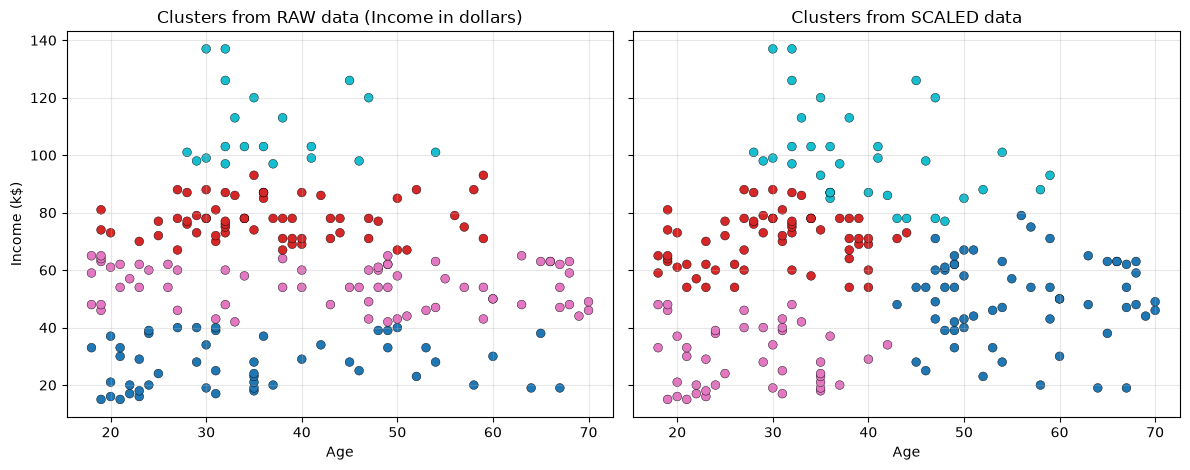

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

ax[0].scatter(Xa[:, 0], Xa[:, 1], c=lab_raw_d, cmap="tab10", s=40, edgecolor="k", linewidth=0.3)
ax[0].set_title("Clusters from RAW data (Income in dollars)")
ax[1].scatter(Xa[:, 0], Xa[:, 1], c=lab_sc_d, cmap="tab10", s=40, edgecolor="k", linewidth=0.3)
ax[1].set_title("Clusters from SCALED data")

for a_ in ax:
    a_.set_xlabel("Age"); a_.grid(alpha=0.3)
ax[0].set_ylabel("Income (k$)")
plt.tight_layout(); plt.show()

**Interpretation:** The four clusters in the left graph represent four flat horizontal lines where the color depends on Income but not on Age. In the right graph, the clusters are based on both Age and Income variables. An ARI value of 0.4897 for the raw data suggests that simply changing the unit resulted in a new clustering. Scaling eliminates the effect of units altogether, and the ARI becomes 1.0.

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

**(a)** The Euclidean distance between two clients is sqrt((Age1 - Age2)^2 + (Income1 - Income2)^2). When the Income variable is measured in dollars, the difference in incomes is in the thousands (difference of 10 k$ is 10,000), and the square of this variable is 100,000,000, whereas the maximum possible difference for Age is 52 years, which equals 2,700. The Age component of the formula becomes negligible, and **Income defines the distance**, with just four clusters of income values.The std is the same as well: 13.97 for Age against 26,265 for Income in dollars. In this case, we got another classification with the k$ approach (**ARI = 0.4897**), but since we are still working with the same data and the same K. The problem was solved with Scaling. After scaling with StandardScaler, the mean of every column became 0 and the std became 1, and z = (x - mean) / std gives the same result regardless of whether we are using income in k$ or dollars, and we get the same clusters for both approaches (**ARI = 1.0**) with equal weight for Age and Income. (Even in k$ Income gets a little bit more weight as it std is 26.26 which is close to double of the std of Age 13.97).

**(b)** The rule of mine is to apply the scaling in case there are features in different units or with different ranges (check the standard deviation or range of columns), since otherwise the large numbers will be determining the clusters. In my view, the scaling should be omitted only in case all features have the same unit and the magnitude is important (such as the coordinates x and y in meters).

---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

WITHOUT the extra customer (200 rows)


,Size,Income,Spending
0,22,25.7,79.4
1,23,26.3,20.9
2,81,55.3,49.5
3,39,86.5,82.1
4,35,88.2,17.1


WITH the extra customer (201 rows)


,Size,Income,Spending
0,23,26.3,20.9
1,100,48.3,56.5
2,39,86.5,82.1
3,38,87.0,18.6
4,1,400.0,99.0


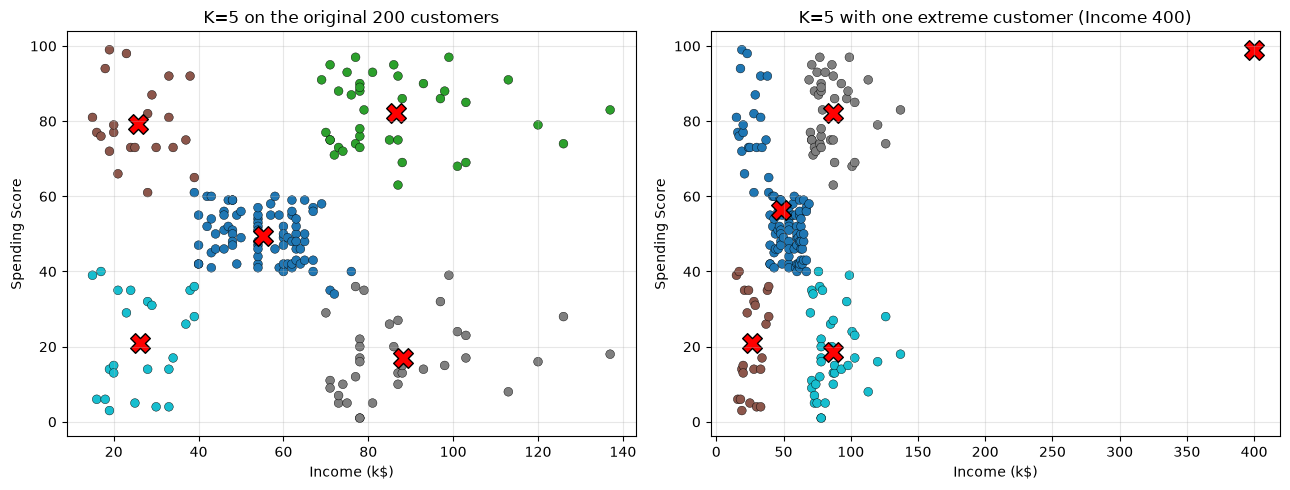

In [38]:
X_out = np.vstack([X2, [400, 99]])          # 201 rows, the last one is the extreme customer

km_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)

def summary(km, title):
    order = np.argsort(km.cluster_centers_[:, 0])         # sort by income
    out = pd.DataFrame(km.cluster_centers_[order].round(1), columns=["Income", "Spending"])
    out.insert(0, "Size", np.bincount(km.labels_, minlength=5)[order])
    print(title)
    display(out)

summary(km_a, "WITHOUT the extra customer (200 rows)")
summary(km_b, "WITH the extra customer (201 rows)")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_a.labels_, cmap="tab10", s=40, edgecolor="k", linewidth=0.3)
ax[0].scatter(*km_a.cluster_centers_.T, c="red", marker="X", s=200, edgecolor="k")
ax[0].set_title("K=5 on the original 200 customers")

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_b.labels_, cmap="tab10", s=40, edgecolor="k", linewidth=0.3)
ax[1].scatter(*km_b.cluster_centers_.T, c="red", marker="X", s=200, edgecolor="k")
ax[1].set_title("K=5 with one extreme customer (Income 400)")

for a_ in ax:
    a_.set_xlabel("Income (k$)"); a_.set_ylabel("Spending Score"); a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation:** We see the five normally distributed groups in the left chart. The right chart shows that one centroid (and one cluster) gets exhausted by the lone individual at Income = 400 while the other 200 individuals must fit into only four clusters. The red Xs are the centroids.

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [39]:
# distance of every real customer to its nearest centroid (model fitted on the 200 real customers)
d_all = km_a.transform(X2).min(axis=1)
d_extra = km_a.transform([[400, 99]]).min(axis=1)[0]

threshold = d_all.mean() + 3 * d_all.std()
print(f"Mean distance = {d_all.mean():.2f}, std = {d_all.std():.2f}, threshold (mean + 3 std) = {threshold:.2f}")
print(f"Distance of the extra customer = {d_extra:.2f}")
print("Extra customer flagged?", d_extra > threshold)

flag = d_all > threshold
print("\nReal customers flagged:", int(flag.sum()))
display(df.loc[flag, ["CustomerID", "Gender", "Age", "Income", "Spending"]].assign(Distance=d_all[flag].round(1)))

Mean distance = 13.02, std = 7.26, threshold (mean + 3 std) = 34.80
Distance of the extra customer = 313.92
Extra customer flagged? True

Real customers flagged: 4


,CustomerID,Gender,Age,Income,Spending,Distance
196,197,Female,45,126,28,39.3
197,198,Male,32,126,74,40.3
198,199,Male,32,137,18,48.8
199,200,Male,30,137,83,50.5


**Interpretation:** The cut-off value is 34.80 while the additional customer is located at a distance of 313.92, which is about nine times the threshold value, hence is detected easily. This pattern also detects four genuine customers (distances 39.3 to 50.5).

**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

**Your answers:**

**(a)** One single client determined the whole outcome. In its absence, the sizes (by income) were 22, 23, 81, 39, 35. In its presence, the sizes became 23, 100, 39, 38, 1. The outlier formed **its own cluster** (size 1, centroid at Income 400, Spending 99), thus wasting one of my 5 clusters on one person. To compensate for this, the low income / high spending group (22 clients, centroid at around 25.7, 79.4) and the middle group (81 clients, centroid at 55.3, 49.5) were **merged** to give a new cluster of 100 clients, centroid at (48.3, 56.5), which does not correspond to either of the two groups. There is also a small shift in high income / low spending centroid (88.2, 17.1 to 87.0, 18.6) and size (35 to 38).

**(b)** Yes, the additional distance is 313.92 and the threshold is 34.80; therefore, this case is definitely an outlier. According to the rule, **4 actual outliers** (ID 197-200; distances 39.3 - 50.5) were marked. These outliers are no mistakes. These are the wealthiest customers in the dataset (with incomes from 126 to 137 k$) located on the very edge of the clusters. Therefore, this is a good rule to mark outlying cases, but any flagged point needs to be checked by a person. (Moreover, distances are not normally distributed, and this is the reason for some real outliers' distances being above mean + 3 std).

**(c)** (1) Firstly, check the point. If it was an entry error in the dataset, then either fix it or delete it; if it was a real point, then do not delete it but try to mitigate its effect, for example, winsorization or logarithmic transformation. (2) It would be wise to apply the algorithm which is more robust to outliers (such as K-Medoids and DBSCAN) or separate the outliers and make them a special "VIP segment" and then cluster all the others. The danger of just removing outliers is that we may actually lose a valuable customer (such as VIP with a huge salary).

---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

,Size,Age,Income,Spending,Segment
Cluster,,,,,
0,81,42.7,55.3,49.5,"Average income, average spending"
1,39,32.7,86.5,82.1,"High income, high spending"
2,22,25.3,25.7,79.4,"Low income, high spending"
3,35,41.1,88.2,17.1,"High income, low spending"
4,23,45.2,26.3,20.9,"Low income, low spending"


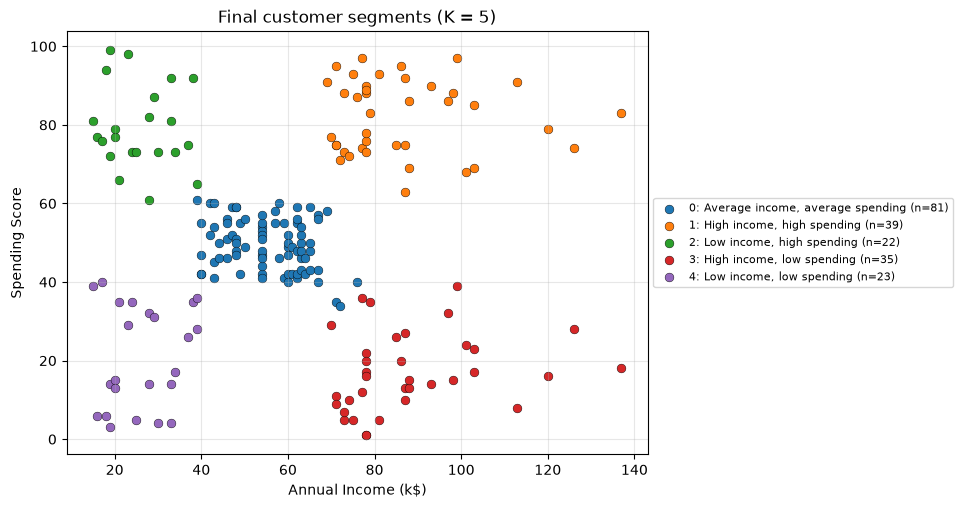

In [40]:
final = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df["Cluster"] = final.labels_

profile = df.groupby("Cluster").agg(
    Size=("CustomerID", "count"),
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Spending=("Spending", "mean"),
).round(1)

# give a name to each cluster from its average Income and Spending
def name_segment(inc, spend):
    level = lambda v, lo, hi: "low" if v <= lo else ("high" if v >= hi else "average")
    i, s = level(inc, 40, 70), level(spend, 35, 65)
    if i == "average" and s == "average":
        return "Average income, average spending"
    return f"{i.capitalize()} income, {s} spending"

profile["Segment"] = [name_segment(r.Income, r.Spending) for r in profile.itertuples()]
df["Segment"] = df["Cluster"].map(profile["Segment"])
display(profile)

plt.figure(figsize=(7.5, 5.5))
for c, row in profile.iterrows():
    mask = df["Cluster"] == c
    plt.scatter(df.loc[mask, "Income"], df.loc[mask, "Spending"], s=40, edgecolor="k", linewidth=0.3,
                label=f"{c}: {row['Segment']} (n={row['Size']})")
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score")
plt.title("Final customer segments (K = 5)")
plt.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5)); plt.grid(alpha=0.3)
plt.show()

**Interpretation:** It is clear from the table above that the five groups are distinguished. The youngest groups are the low-income high-spenders (25.3 years on average) and the high-income high-spenders (32.7 years), while the oldest one is the low-income low-spenders (45.2 years). The largest group is the average group, which consists of 81 clients (40.5%).

**Segment names and actions** (one line per cluster)

| Cluster | Segment name | Marketing action |
|---|---|---|
| 0 | Average income, average spending (81 customers, avg age 42.7) | Loyalty card with points and seasonal bundles, to move them slowly towards higher spending. |
| 1 | High income, high spending (39 customers, avg age 32.7) | VIP programme: early access to new collections, personal offers and premium events. These are the most valuable customers, so keep them. |
| 2 | Low income, high spending (22 customers, avg age 25.3) | Student/young shopper discounts, instalment offers and social media campaigns. They like to spend even with a low income. |
| 3 | High income, low spending (35 customers, avg age 41.1) | Personalised promotions on premium brands and a short survey to find out why they spend so little although they can afford more. |
| 4 | Low income, low spending (23 customers, avg age 45.2) | Low-cost actions only: discount coupons and clearance sale messages, without spending much marketing budget on them. |

### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [41]:
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)

print("Saved customer_segments.csv with shape", out.shape)
display(out.head())
print("\nCustomers per segment:")
print(out["Segment"].value_counts())

Saved customer_segments.csv with shape (200, 7)


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,"Low income, low spending"
1,2,21,Male,15,81,2,"Low income, high spending"
2,3,20,Female,16,6,4,"Low income, low spending"
3,4,23,Female,16,77,2,"Low income, high spending"
4,5,31,Female,17,40,4,"Low income, low spending"



Customers per segment:
Segment
Average income, average spending    81
High income, high spending          39
High income, low spending           35
Low income, low spending            23
Low income, high spending           22
Name: count, dtype: int64


**Interpretation:** The dataset has one line per customer (200 lines) having the cluster ID and the segment name, which means that the marketing department can open the file in Excel without executing this notebook.

**Executive Summary** (4–6 lines)

I used **K = 5** clusters for the Mall Customers based on Income and Spending because there is an elbow bend at K = 5 (inertia decreases from 29,231 when going from K=4 to 5 and increases only 7,215 when increasing K from 5 to 6), and the average silhouette value is highest at K = 5 (0.554). There are five clusters: average income/average spending (81 clients), high income/high spending (39), high income/low spending (35), low income/low spending (23) and low income/high spending (22), each with different marketing campaign. Since Income and Spending both have values from 0 to 100 (std is 26.3 and 25.8), there was no need to scale them, but Part 4 experiment proved that it was crucial in the case when variables had different units (ARI between k$ and dollar versions was only 0.49 for unscaled version, 1.0 for scaled one). K-means++ is implemented with `n_init=10` so that the results are consistent (inertia is 44448.5 for all 30 seeds), and I searched for outliers using mean + 3 * std rule; the four customers marked as outliers (with very high incomes) are real and I did not delete them. A weakness is that it consists of just 200 customers of one mall, and I used just two variables, hence Age and Gender do not enter segmentation.

---

### Before you submit
- [ ] Restart the kernel and **Run All**: the notebook runs top to bottom without errors.
- [ ] Every table and plot has 1–3 lines of interpretation below it.
- [ ] All questions are answered with your own numbers.
- [ ] Student Information block is filled in.
- [ ] Notebook and `customer_segments.csv` are pushed to your GitHub repository.